<a href="https://colab.research.google.com/github/sofilukash/decision_trees_and_forests_of_decision_trees_lab2/blob/main/decision_trees_and_forests_of_decision_trees.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Дерево рішень і ліс дерев рішень в системах машинного навчання

**Мета:** застосувати дерево рішень (ДР) і випадковий ліс (RF) до трьох датасетів із Kaggle, проаналізувати переваги та недоліки алгоритмів і зробити висновки про якість класифікації залежно від особливостей даних.

**План:** датасети → підготовка → моделі та метрики (усереднення за 5 розбиттями) → матриці спряженості → стабільність → дисбаланс класів → інформаційний приріст, важливість ознак і правила дерева → висновки.


## 1. Датасети та налаштування
Обрано три датасети тематики *security* з Kaggle з **різними властивостями даних**, щоб побачити, як вони впливають на якість класифікації:

| Датасет | Kaggle | Особливість даних |
|---|---|---|
| Network Intrusion Detection | [sampadab17/network-intrusion-detection](https://www.kaggle.com/datasets/sampadab17/network-intrusion-detection) | мережеві з'єднання; змішані ознаки (числові + 3 категоріальні), класи збалансовані |
| Phishing website Detector | [eswarchandt/phishing-website-detector](https://www.kaggle.com/datasets/eswarchandt/phishing-website-detector) | ознаки URL/сторінки; усі ознаки дискретні (−1/0/1), класи збалансовані |
| Credit Card Fraud Detection | [mlg-ulb/creditcardfraud](https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud) | шахрайські транзакції; **сильний дисбаланс**, ознаки V1–V28 — анонімізовані PCA-компоненти |

Credit Card Fraud — це безпека фінансових транзакцій, а не мережева атака; його взято як контрастний випадок із сильним дисбалансом класів.

Позитивний клас (1) = атака / фішинг / шахрайство.

In [1]:
!pip install -q kagglehub
import time, warnings
from pathlib import Path
import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display, Markdown
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, average_precision_score, f1_score, precision_score,S
                             precision_recall_curve, recall_score, roc_auc_score, ConfusionMatrixDisplay)
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree

warnings.filterwarnings("ignore")
SEED = 42          # перше розбиття: на ньому будуються матриці спряженості, дерева, важливість ознак
N_SPLITS = 5       # кількість стратифікованих розбиттів 70/30 для усереднення метрик (мінімум 3)
SEEDS = [SEED] + list(range(1, N_SPLITS))
MAX_ROWS = 60_000  # ліміт рядків для швидкості: весь рідкісний клас зберігається, скорочується лише більшість (None = без ліміту)

DATASETS = [
    dict(name="Network Intrusion", slug="sampadab17/network-intrusion-detection",
         file="Train_data.csv", target="class", positive="anomaly", drop=[]),
    dict(name="Phishing Websites", slug="eswarchandt/phishing-website-detector",
         file="phishing.csv", target="class", positive="-1", drop=["Index"]),   # -1 = phishing
    dict(name="Credit Card Fraud", slug="mlg-ulb/creditcardfraud",
         file="creditcard.csv", target="Class", positive="1", drop=[]),
]

## 2. Завантаження та підготовка даних
- `kagglehub` сам завантажує датасет.
- Видаляємо **дублікати** (інакше однакові рядки потрапляють і в train, і в test, що завищує якість). Кількість видалених рядків наведено в таблиці — це теж властивість даних.
- Ціль → 0/1; категоріальні ознаки → **one-hot** (дерева не працюють з текстом); пропуски (якщо є) → медіана.
- Якщо рядків більше за `MAX_ROWS`, скорочується лише більшість класу: **усі** приклади рідкісного класу залишаються. Так у тесті лишається достатньо позитивних прикладів для надійної оцінки.

In [2]:
def load(ds):
    try:
        folder = kagglehub.dataset_download(ds["slug"])
    except Exception as e:  # потрібна авторизація Kaggle
        print(f"Потрібна авторизація Kaggle ({type(e).__name__}): введіть username та API-токен")
        kagglehub.login()
        folder = kagglehub.dataset_download(ds["slug"])
    path = next(Path(folder).rglob(ds["file"]), None)
    if path is None:
        raise FileNotFoundError(f"{ds['file']} не знайдено: {[p.name for p in Path(folder).rglob('*.csv')]}")
    df = pd.read_csv(path)
    df.columns = df.columns.str.strip()
    return df


def cap_rows(X, y, max_rows):
    # Залишає всі приклади рідкісного класу, скорочує лише більшість до max_rows рядків загалом.
    if not max_rows or len(X) <= max_rows:
        return X, y
    minority = y.value_counts().idxmin()
    keep_min = y.index[y == minority]
    keep_maj = y[y != minority].sample(n=max_rows - len(keep_min), random_state=SEED).index
    idx = keep_min.union(keep_maj)
    return X.loc[idx].reset_index(drop=True), y.loc[idx].reset_index(drop=True)


def prepare(df, ds):
    if ds["target"] not in df.columns:
        raise KeyError(f"Колонки '{ds['target']}' немає: {list(df.columns)}")
    raw, nan = len(df), int(df.isna().sum().sum())
    df = df.drop(columns=ds["drop"], errors="ignore").drop_duplicates()
    dedup = len(df)
    y = (df[ds["target"]].astype(str).str.strip() == ds["positive"]).astype(int)
    X = df.drop(columns=ds["target"])
    n_cat = X.select_dtypes(exclude="number").shape[1]
    X = pd.get_dummies(X, dtype=float)
    X = X.fillna(X.median())   # у цих датасетах пропусків немає (див. таблицю), тож на результат не впливає
    X, y = cap_rows(X, y, MAX_ROWS)
    info = dict(raw=raw, dups=raw - dedup, rows=len(X), features=X.shape[1], categorical=n_cat,
                nan=nan, positives=int(y.sum()), positive_pct=100 * y.mean())
    return X, y, info


DATA, INFO = {}, {}
for ds in DATASETS:
    X, y, info = prepare(load(ds), ds)
    DATA[ds["name"]], INFO[ds["name"]] = (X, y), info

display(pd.DataFrame.from_dict(INFO, orient="index").rename(columns={
    "raw": "рядків у файлі", "dups": "видалено дублікатів", "rows": "рядків у роботі",
    "features": "ознак (після кодування)", "categorical": "категоріальних (до кодування)",
    "nan": "пропусків", "positives": "позитивних", "positive_pct": "позитивний клас, %"}).round(2))

100%|██████████| 818k/818k [00:00<00:00, 1.66MB/s]

Extracting files...


100%|██████████| 197k/197k [00:00<00:00, 705kB/s]

Extracting files...


Using Colab cache for faster access to the 'creditcardfraud' dataset.


,рядків у файлі,видалено дублікатів,рядків у роботі,ознак (після кодування),категоріальних (до кодування),пропусків,позитивних,"позитивний клас, %"
Network Intrusion,25192,0,25192,118,3,0,11743,46.61
Phishing Websites,11054,5205,5849,30,0,0,3019,51.62
Credit Card Fraud,284807,1081,60000,30,0,0,473,0.79


## 3. Моделі та метрики
**Протокол.** `N_SPLITS` стратифікованих розбиттів train/test = 70/30 з різними `random_state` (перше — `SEED`). Усі таблиці нижче показують **середнє ± std за розбиттями**: один тест із кількома десятками рідкісних прикладів дає занадто випадковий результат. Гіперпараметри обрізаного дерева підбираються всередині кожного розбиття лише на train.

**Моделі:**
1. **ДР повне (gini)** і **ДР повне (entropy)** — два критерії якості розбиття: індекс Джині `1 − Σpᵢ²` та ентропія Шеннона `−Σpᵢ·log pᵢ` (обидва = 0 для «чистого» вузла).
2. **ДР обрізане** — `max_depth`, `min_samples_leaf` і `ccp_alpha` (cost-complexity pruning) підбираються на крос-валідації (CV=3) за F1; це захист від перенавчання.
3. **Random Forest** — 100 дерев: **беггінг** (бутстреп-вибірки з поверненням) + випадкова підмножина ознак у кожному вузлі; прогноз — голосування.
4. **Random Forest (class_weight)** — лише для датасетів із часткою позитивного класу < 5%: той самий ліс зі збалансованими вагами класів.

**Метрики:** precision, recall, F1, ROC-AUC, PR-AUC. При дисбалансі accuracy оманлива, тому дивимось recall/F1/PR-AUC. `train_f1` показує перенавчання (train ≫ test). `leaves` — кількість листків (для лісу — середнє по деревах); `fit_s` для обрізаного ДР включає підбір параметрів.

Повне (необрізане) дерево видає майже лише 0/1 замість ймовірностей, тому його ROC-AUC і PR-AUC фактично відповідають одній робочій точці й не є повноцінною оцінкою ранжування. Коректно порівнювати AUC обрізаного дерева з лісом.

In [3]:
GRID = {"max_depth": [4, 8, 12], "min_samples_leaf": [1, 5], "ccp_alpha": [0, 1e-4, 1e-3]}


def evaluate(est, Xtr, ytr, Xte, yte):
    p, s = est.predict(Xte), est.predict_proba(Xte)[:, 1]
    return dict(train_f1=f1_score(ytr, est.predict(Xtr), zero_division=0),
                accuracy=accuracy_score(yte, p), precision=precision_score(yte, p, zero_division=0),
                recall=recall_score(yte, p, zero_division=0), f1=f1_score(yte, p, zero_division=0),
                roc_auc=roc_auc_score(yte, s), pr_auc=average_precision_score(yte, s)), p


def n_leaves(est):
    if hasattr(est, "estimators_"):
        return float(np.mean([t.get_n_leaves() for t in est.estimators_]))
    return est.get_n_leaves()


def make_rf(seed, **kw):
    return RandomForestClassifier(n_estimators=100, max_features="sqrt", bootstrap=True,
                                  oob_score=True, n_jobs=-1, random_state=seed, **kw)


RUNS, DEMO = [], {}
for name, (X, y) in DATA.items():
    t0 = time.time()
    imbalanced = INFO[name]["positive_pct"] < 5
    for seed in SEEDS:
        Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, stratify=y, random_state=seed)
        models = {
            "DT повне (gini)": DecisionTreeClassifier(criterion="gini", random_state=seed),
            "DT повне (entropy)": DecisionTreeClassifier(criterion="entropy", random_state=seed),
            "DT обрізане": GridSearchCV(DecisionTreeClassifier(random_state=seed), GRID,
                                        scoring="f1", cv=3, n_jobs=-1),
            "Random Forest": make_rf(seed),
        }
        if imbalanced:
            models["Random Forest (class_weight)"] = make_rf(seed, class_weight="balanced_subsample")
        ests, preds = {}, {}
        for m_name, m in models.items():
            t = time.time()
            m.fit(Xtr, ytr)
            est = getattr(m, "best_estimator_", m)
            res, preds[m_name] = evaluate(est, Xtr, ytr, Xte, yte)
            RUNS.append(dict(dataset=name, model=m_name, seed=seed, **res,
                             leaves=n_leaves(est), fit_s=time.time() - t))
            ests[m_name] = est
        if seed == SEED:   # демонстраційне розбиття для матриць, дерев, важливості ознак
            DEMO[name] = dict(ests=ests, preds=preds, Xte=Xte, yte=yte, ytr=ytr, cols=list(X.columns),
                              best=models["DT обрізане"].best_params_)
    print(f"{name}: готово за {time.time() - t0:.0f} с; параметри обрізаного ДР (розбиття seed={SEED}) = {DEMO[name]['best']}")

RUNS_DF = pd.DataFrame(RUNS)


def summary_table(df):
    rows = []
    for (d, m), g in df.groupby(["dataset", "model"], sort=False):
        row = {"Датасет": d, "Модель": m}
        for c in ["train_f1", "accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc"]:
            row[c] = f"{g[c].mean():.3f} ± {g[c].std():.3f}"
        row["leaves"], row["fit_s"] = f"{g['leaves'].mean():.0f}", f"{g['fit_s'].mean():.1f}"
        rows.append(row)
    return pd.DataFrame(rows).set_index(["Датасет", "Модель"])


display(summary_table(RUNS_DF))

Network Intrusion: готово за 15 с; параметри обрізаного ДР (розбиття seed=42) = {'ccp_alpha': 0.0001, 'max_depth': 12, 'min_samples_leaf': 1}
Phishing Websites: готово за 3 с; параметри обрізаного ДР (розбиття seed=42) = {'ccp_alpha': 0.0001, 'max_depth': 12, 'min_samples_leaf': 1}
Credit Card Fraud: готово за 180 с; параметри обрізаного ДР (розбиття seed=42) = {'ccp_alpha': 0, 'max_depth': 4, 'min_samples_leaf': 1}


train_f1       accuracy  \
Датасет           Модель                                                       
Network Intrusion DT повне (gini)               1.000 ± 0.000  0.996 ± 0.001   
                  DT повне (entropy)            1.000 ± 0.000  0.996 ± 0.000   
                  DT обрізане                   0.999 ± 0.000  0.996 ± 0.001   
                  Random Forest                 1.000 ± 0.000  0.997 ± 0.001   
Phishing Websites DT повне (gini)               0.993 ± 0.001  0.915 ± 0.010   
                  DT повне (entropy)            0.993 ± 0.001  0.917 ± 0.009   
                  DT обрізане                   0.951 ± 0.016  0.925 ± 0.006   
                  Random Forest                 0.993 ± 0.001  0.942 ± 0.007   
Credit Card Fraud DT повне (gini)               1.000 ± 0.000  0.996 ± 0.000   
                  DT повне (entropy)            1.000 ± 0.000  0.996 ± 0.001   
                  DT обрізане                   0.887 ± 0.007  0.998 ± 0.000   
                  Random Forest                 1.000 ± 0.001  0.998 ± 0.000   
                  Random Forest (class_weight)  1.000 ± 0.001  0.998 ± 0.000   

                                                    precision         recall  \
Датасет           Модель                                                       
Network Intrusion DT повне (gini)               0.997 ± 0.001  0.995 ± 0.001   
                  DT повне (entropy)            0.996 ± 0.001  0.995 ± 0.001   
                  DT обрізане                   0.996 ± 0.002  0.995 ± 0.001   
                  Random Forest                 0.999 ± 0.000  0.995 ± 0.001   
Phishing Websites DT повне (gini)               0.922 ± 0.009  0.913 ± 0.017   
                  DT повне (entropy)            0.927 ± 0.010  0.911 ± 0.011   
                  DT обрізане                   0.935 ± 0.005  0.918 ± 0.010   
                  Random Forest                 0.950 ± 0.003  0.937 ± 0.013   
Credit Card Fraud DT повне (gini)               0.758 ± 0.022  0.817 ± 0.020   
                  DT повне (entropy)            0.753 ± 0.051  0.815 ± 0.034   
                  DT обрізане                   0.933 ± 0.011  0.817 ± 0.021   
                  Random Forest                 0.949 ± 0.022  0.830 ± 0.014   
                  Random Forest (class_weight)  0.959 ± 0.015  0.792 ± 0.023   

                                                           f1        roc_auc  \
Датасет           Модель                                                       
Network Intrusion DT повне (gini)               0.996 ± 0.001  0.996 ± 0.001   
                  DT повне (entropy)            0.995 ± 0.000  0.996 ± 0.000   
                  DT обрізане                   0.996 ± 0.001  0.996 ± 0.001   
                  Random Forest                 0.997 ± 0.001  1.000 ± 0.000   
Phishing Websites DT повне (gini)               0.918 ± 0.010  0.920 ± 0.010   
                  DT повне (entropy)            0.919 ± 0.009  0.921 ± 0.010   
                  DT обрізане                   0.927 ± 0.006  0.970 ± 0.013   
                  Random Forest                 0.943 ± 0.007  0.987 ± 0.003   
Credit Card Fraud DT повне (gini)               0.786 ± 0.018  0.907 ± 0.010   
                  DT повне (entropy)            0.782 ± 0.030  0.907 ± 0.017   
                  DT обрізане                   0.871 ± 0.013  0.909 ± 0.022   
                  Random Forest                 0.885 ± 0.011  0.967 ± 0.011   
                  Random Forest (class_weight)  0.867 ± 0.013  0.967 ± 0.008   

                                                       pr_auc leaves fit_s  
Датасет           Модель                                                    
Network Intrusion DT повне (gini)               0.994 ± 0.001     90   0.1  
                  DT повне (entropy)            0.993 ± 0.001     76   0.1  
                  DT обрізане                   0.995 ± 0.002     59   2.2  
                  Random Forest                 1.000 ± 0.000    

## 4. Матриці спряженості
Показано розбиття `seed=42`. Рядки — справжній клас, стовпці — прогноз. Поза діагоналлю помилки: **FP** (хибна тривога, верхній правий кут) та **FN** (пропущена атака, нижній лівий кут). Для задач безпеки FN зазвичай дорожчі.

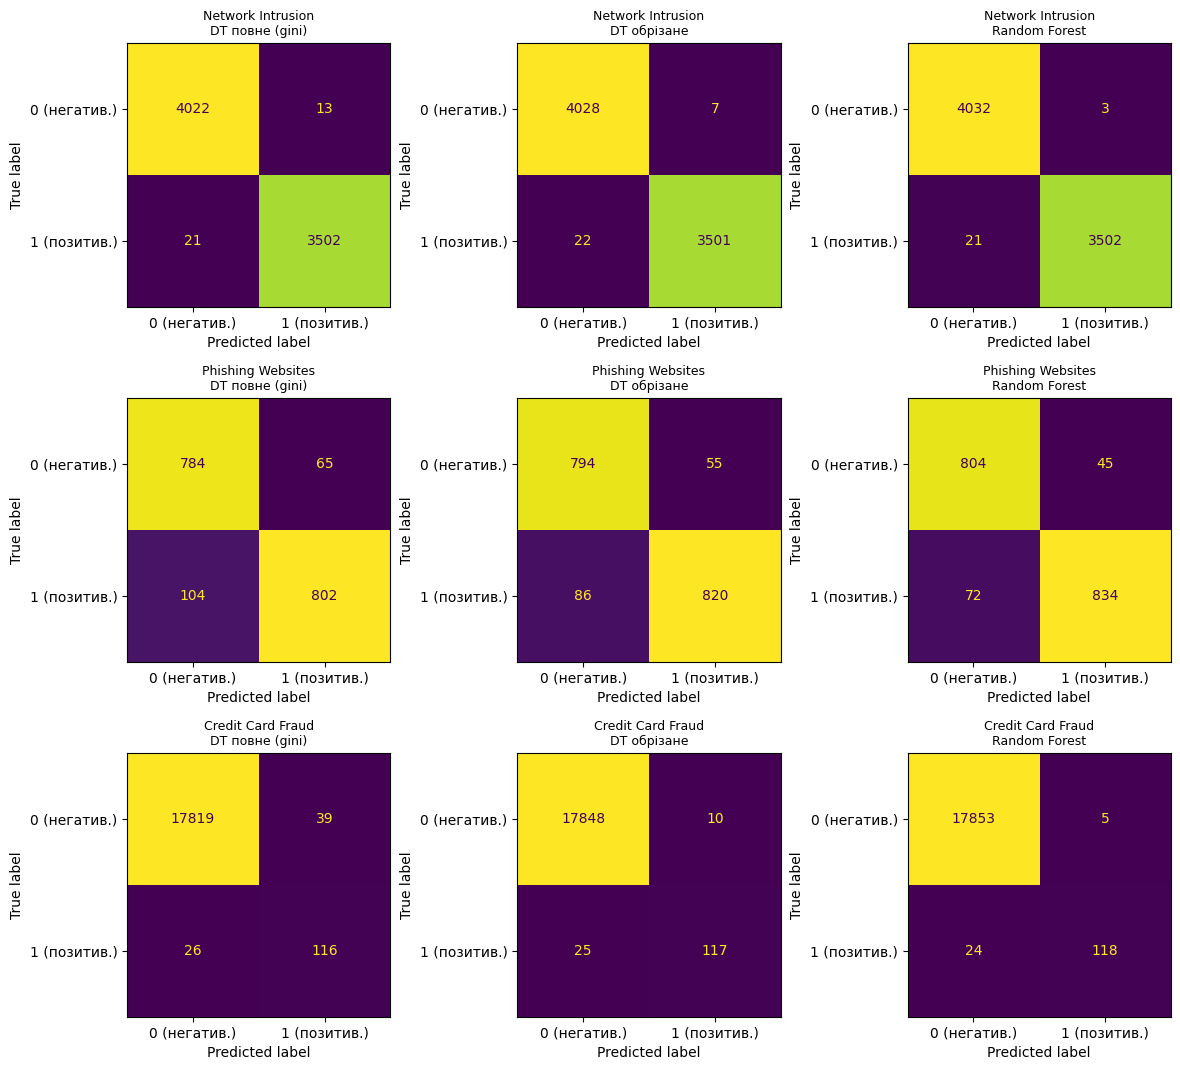

In [4]:
show = ["DT повне (gini)", "DT обрізане", "Random Forest"]
fig, ax = plt.subplots(len(DEMO), 3, figsize=(12, 3.6 * len(DEMO)))
for i, (name, r) in enumerate(DEMO.items()):
    for j, m in enumerate(show):
        ConfusionMatrixDisplay.from_predictions(r["yte"], r["preds"][m], ax=ax[i, j], colorbar=False,
                                                values_format="d", display_labels=["0 (негатив.)", "1 (позитив.)"])
        ax[i, j].set_title(f"{name}\n{m}", fontsize=9)
plt.tight_layout()
plt.show()

## 5. Стабільність
Нижче — F1 кожної моделі на кожному з розбиттів (точки) та середнє (червоний ромб). Розкид точок — це нестабільність: наскільки сильно змінюється якість при новій навчальній вибірці. Так перевіряється недолік дерева (нестабільність) і ефект усереднення (беггінг) у лісі, а також чи зменшує розкид обрізання. Шкали осей у панелях різні (наприклад, на Network весь розкид близько 0.003), тому порівнювати слід розкид усередині панелі.

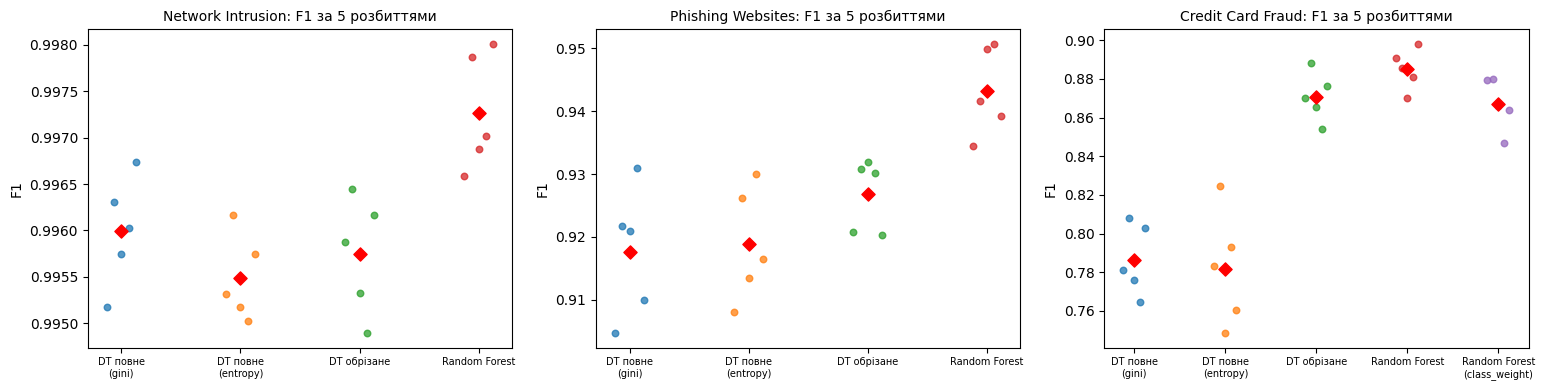

In [5]:
fig, ax = plt.subplots(1, len(DEMO), figsize=(5.2 * len(DEMO), 4))
for a, name in zip(np.atleast_1d(ax), DEMO):
    sub = RUNS_DF[RUNS_DF["dataset"] == name]
    models = list(dict.fromkeys(sub["model"]))
    for k, m in enumerate(models):
        v = sub.loc[sub["model"] == m, "f1"].to_numpy()
        a.scatter(np.full(len(v), k) + np.linspace(-0.12, 0.12, len(v)), v, s=22, alpha=0.75)
        a.scatter(k, v.mean(), marker="D", color="red", s=45, zorder=3)
    a.set_xticks(range(len(models)))
    a.set_xticklabels([m.replace(" (", "\n(") for m in models], fontsize=7)
    a.set_title(f"{name}: F1 за {len(SEEDS)} розбиттями", fontsize=10)
    a.set_ylabel("F1")
plt.tight_layout()
plt.show()

## 6. Дисбаланс класів: вплив `class_weight` і порога
Лише для датасетів із часткою позитивного класу < 5%. При дисбалансі модель за порога 0.5 може пропускати рідкісний клас. Перевіряємо, чи допомагають два способи: **вагу класів** (`class_weight`) і **підбір порога** класифікації. Поріг обирається за максимумом F1 на OOB-ймовірностях навчальної вибірки (тест не використовується) і застосовується до тесту. Розбиття `seed=42`.

In [6]:
rows = []
for name, r in DEMO.items():
    if INFO[name]["positive_pct"] >= 5:
        continue
    for m in ("Random Forest", "Random Forest (class_weight)"):
        est = r["ests"][m]
        oob = np.nan_to_num(est.oob_decision_function_[:, 1])
        pr, rc, thr = precision_recall_curve(r["ytr"], oob)
        t_best = thr[np.argmax(2 * pr[:-1] * rc[:-1] / (pr[:-1] + rc[:-1] + 1e-12))]
        proba = est.predict_proba(r["Xte"])[:, 1]
        for label, t in (("0.50", 0.5), (f"{t_best:.2f} (підібраний)", t_best)):
            p = (proba >= t).astype(int)
            rows.append({"Датасет": name, "Модель": m, "Поріг": label,
                         "precision": precision_score(r["yte"], p, zero_division=0),
                         "recall": recall_score(r["yte"], p, zero_division=0),
                         "F1": f1_score(r["yte"], p, zero_division=0),
                         "FN (пропущено)": int(((r["yte"] == 1) & (p == 0)).sum()),
                         "FP (хибні тривоги)": int(((r["yte"] == 0) & (p == 1)).sum())})
display(pd.DataFrame(rows).set_index(["Датасет", "Модель", "Поріг"]).round(3))

precision  \
Датасет           Модель                       Поріг                          
Credit Card Fraud Random Forest                0.50                   0.959   
                                               0.56 (підібраний)      0.967   
                  Random Forest (class_weight) 0.50                   0.983   
                                               0.33 (підібраний)      0.952   

                                                                  recall  \
Датасет           Модель                       Поріг                       
Credit Card Fraud Random Forest                0.50                0.831   
                                               0.56 (підібраний)   0.824   
                  Random Forest (class_weight) 0.50                0.796   
                                               0.33 (підібраний)   0.831   

                                                                     F1  \
Датасет           Модель                       Поріг                      
Credit Card Fraud Random Forest                0.50               0.891   
                                               0.56 (підібраний)  0.890   
                  Random Forest (class_weight) 0.50               0.879   
                                               0.33 (підібраний)  0.887   

                                                                  FN (пропущено)  \
Датасет           Модель                       Поріг                               
Credit Card Fraud Random Forest                0.50                           24   
                                               0.56 (підібраний)              25   
                  Random Forest (class_weight) 0.50                           29   
                                               0.33 (підібраний)              24   

                                                                  FP (хибні тривоги)  
Датасет           Модель                       Поріг                                  
Credit Card Fraud Random Forest                0.50                                5  
                                               0.56 (підібраний)                   4  
                  Random Forest (class_weight) 0.50                                2  
                                               0.33 (підібраний)                   6

## 7. Інтерпретація: інформаційний приріст, важливість ознак і структура дерева
**7.1 Приріст якості розбиття у корені.** Для повних дерев (розбиття `seed=42`) показано нечистоту кореня `I(корінь)`, середньозважену нечистоту двох нащадків `I(після)` і приріст = `I(корінь) − I(після)`. Для `entropy` це **інформаційний приріст** (у бітах), для `gini` — зменшення індексу Джині. Чим більший приріст, тим краще перший тест розділяє класи.

In [7]:
def impurity(t, i, kind):
    v = t.value[i][0].astype(float)
    p = v / v.sum()
    if kind == "gini":
        return 1 - np.sum(p ** 2)
    p = p[p > 0]
    return -np.sum(p * np.log2(p))


rows = []
for name, r in DEMO.items():
    for kind in ("gini", "entropy"):
        t = r["ests"][f"DT повне ({kind})"].tree_
        l, rr = t.children_left[0], t.children_right[0]
        n, nl, nr = t.weighted_n_node_samples[[0, l, rr]]
        i0 = impurity(t, 0, kind)
        after = (nl * impurity(t, l, kind) + nr * impurity(t, rr, kind)) / n
        rows.append({"Датасет": name, "Критерій": kind, "Ознака кореня": r["cols"][t.feature[0]],
                     "Поріг": t.threshold[0], "I(корінь)": i0, "I(після)": after, "Приріст": i0 - after})
display(pd.DataFrame(rows).set_index(["Датасет", "Критерій"]).round(3))

Ознака кореня   Поріг  I(корінь)  I(після)  Приріст
Датасет           Критерій                                                    
Network Intrusion gini         src_bytes  28.500      0.498     0.142    0.355
                  entropy      src_bytes  28.500      0.997     0.392    0.605
Phishing Websites gini             HTTPS   0.500      0.499     0.206    0.294
                  entropy          HTTPS   0.500      0.999     0.517    0.482
Credit Card Fraud gini               V17  -2.505      0.016     0.006    0.010
                  entropy            V14  -3.792      0.066     0.025    0.042

**7.2 Важливість ознак і правила дерева.**
- Стовпчики — внесок ознак у зменшення нечистоти (RF усереднює по всіх деревах). Це міра за нечистотою: вона дещо зміщена на користь неперервних ознак із багатьма порогами.
- Нижче — перші три рівні обрізаного дерева: читабельні правила `якщо ознака ≤ поріг`, головна перевага ДР перед лісом.
- У Credit Card ознаки V1–V28 — анонімізовані PCA-компоненти, тому правила на кшталт `V14 ≤ …` не мають змістовної інтерпретації; у Network Intrusion і Phishing ознаки називаються зрозуміло, і правила можна читати як ознаки атаки/фішингу.

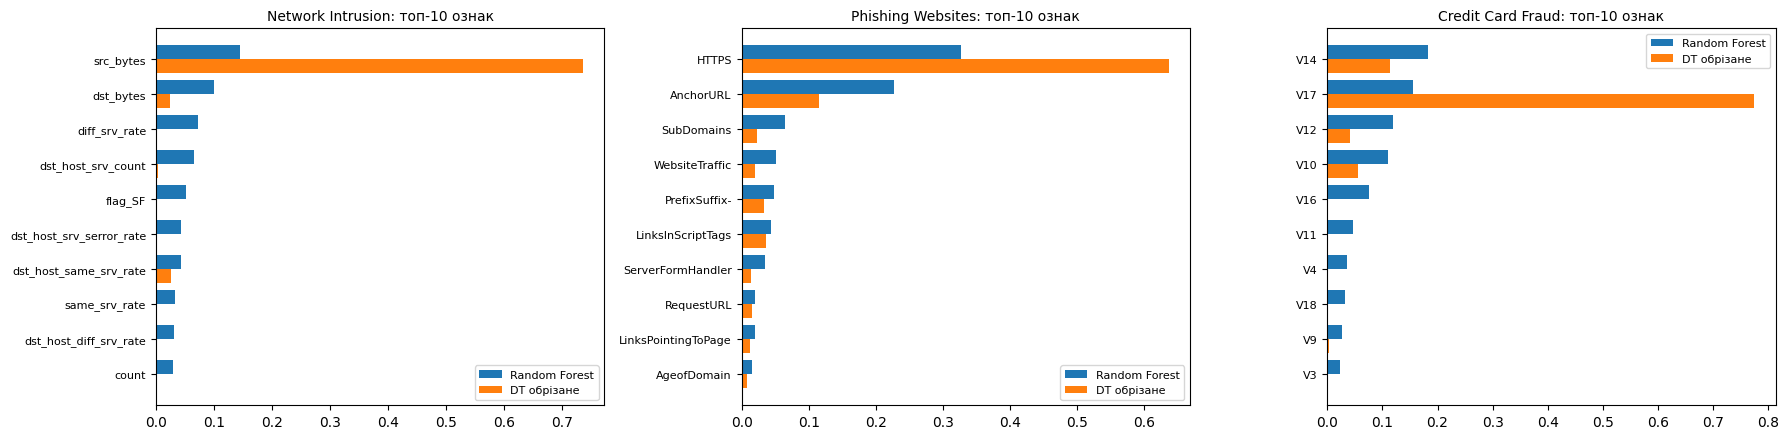

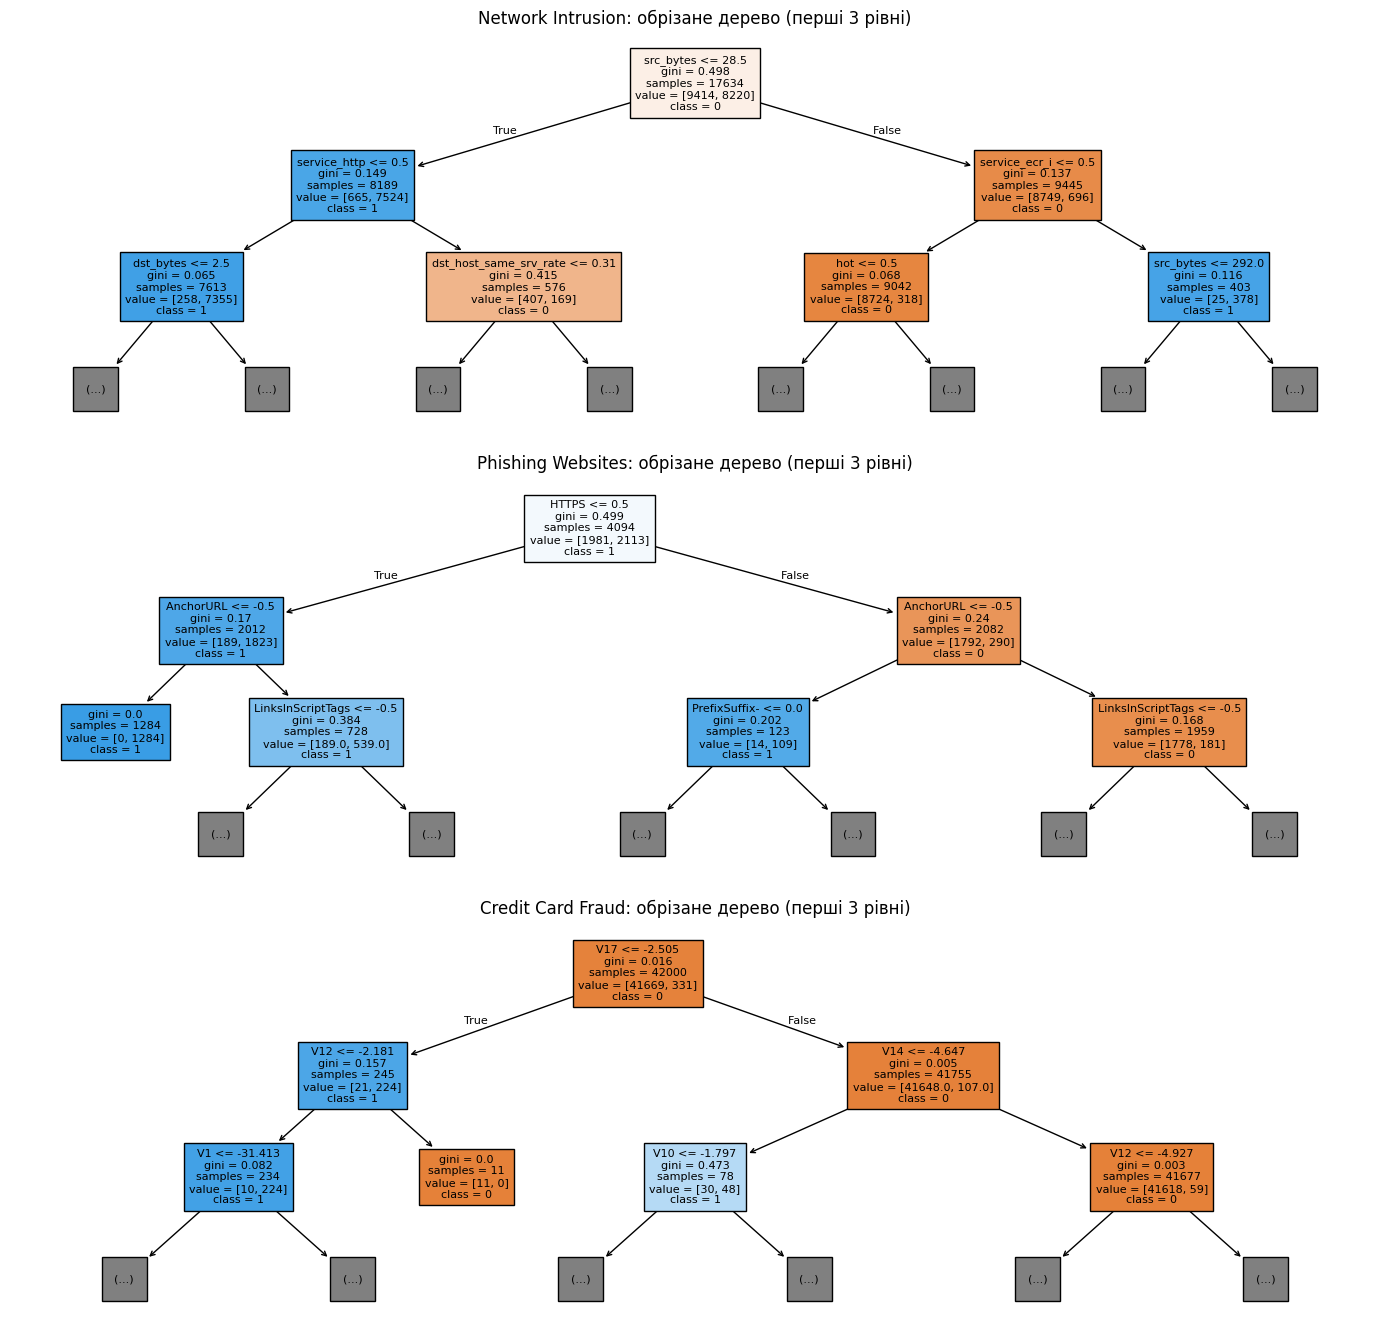

In [8]:
fig, ax = plt.subplots(1, len(DEMO), figsize=(6 * len(DEMO), 4.5))
for a, (name, r) in zip(np.atleast_1d(ax), DEMO.items()):
    rf = pd.Series(r["ests"]["Random Forest"].feature_importances_, r["cols"])
    dt = pd.Series(r["ests"]["DT обрізане"].feature_importances_, r["cols"])
    top = rf.nlargest(10).index[::-1]
    pos = np.arange(len(top))
    a.barh(pos + 0.2, rf[top], 0.4, label="Random Forest")
    a.barh(pos - 0.2, dt[top], 0.4, label="DT обрізане")
    a.set_yticks(pos)
    a.set_yticklabels(top, fontsize=8)
    a.set_title(f"{name}: топ-10 ознак", fontsize=10)
    a.legend(fontsize=8)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(len(DEMO), 1, figsize=(14, 4.5 * len(DEMO)))
for a, (name, r) in zip(ax, DEMO.items()):
    plot_tree(r["ests"]["DT обрізане"], feature_names=r["cols"], class_names=["0", "1"], filled=True,
              max_depth=2, fontsize=8, ax=a)
    a.set_title(f"{name}: обрізане дерево (перші 3 рівні)")
plt.tight_layout()
plt.show()

## 8. Висновки
**8.1 Числові результати.** Формуються автоматично з таблиць вище. Різниця між моделями називається *стабільною*, якщо вона не менша за 0.005 і перевищує 2 стандартні похибки середнього за розбиттями; інакше вона *в межах розкиду*. Розбиття перекриваються (це не незалежні вибірки), тому критерій — практична евристика, а не формальний статистичний тест.

In [9]:
def col(name, model, metric):
    d = RUNS_DF[(RUNS_DF["dataset"] == name) & (RUNS_DF["model"] == model)].sort_values("seed")
    return d[metric].to_numpy()


def paired(name, a, b, metric="f1"):
    d = col(name, a, metric) - col(name, b, metric)
    sem = d.std(ddof=1) / np.sqrt(len(d)) if len(d) > 1 else np.nan
    stable = bool(abs(d.mean()) >= 0.005 and abs(d.mean()) > 2 * sem)
    return d.mean(), ("різниця стабільна" if stable else "різниця в межах розкиду")


def sg(x):
    return "0.000" if abs(x) < 0.0005 else f"{x:+.3f}"


G, E, P, F, FW = "DT повне (gini)", "DT повне (entropy)", "DT обрізане", "Random Forest", "Random Forest (class_weight)"


def conclusions(name):
    r, i = DEMO[name], INFO[name]
    m = lambda mod, met: col(name, mod, met).mean()
    s = lambda mod: col(name, mod, "f1").std(ddof=1)
    L = []
    gap = m(G, "train_f1") - m(G, "f1")
    L.append(f"Повне дерево: F1 train = {m(G, 'train_f1'):.3f}, test = {m(G, 'f1'):.3f} (розрив {gap:.3f}) — "
             + ("виражене перенавчання." if gap > 0.05 else "помірне перенавчання." if gap > 0.01 else "перенавчання слабке."))
    d, v = paired(name, G, E)
    L.append(f"gini vs entropy: ΔF1 (gini − entropy) = {sg(d)} — {v}.")
    d, v = paired(name, P, G)
    L.append(f"Обрізання: листків {m(G, 'leaves'):.0f} → {m(P, 'leaves'):.0f}, ΔF1 = {sg(d)} — {v}.")
    best_dt = max((G, P), key=lambda mod: m(mod, "f1"))
    d, v = paired(name, F, best_dt)
    dpr, _ = paired(name, F, P, "pr_auc")
    L.append(f"Random Forest vs найкраще дерево ({best_dt}): ΔF1 = {sg(d)} — {v}; ΔPR-AUC відносно обрізаного дерева = {sg(dpr)}.")
    L.append(f"Стабільність (std F1 за розбиттями): DT повне {s(G):.4f}, DT обрізане {s(P):.4f}, RF {s(F):.4f}.")
    if i["positive_pct"] < 5:
        base = 100 - i["positive_pct"]
        L.append(f"Сильний дисбаланс ({i['positive_pct']:.2f}%): accuracy RF = {m(F, 'accuracy'):.4f} при {base:.2f}% у «класифікатора, що завжди каже 0» — "
                 f"accuracy майже не інформативна. Recall: DT {m(G, 'recall'):.3f}, RF {m(F, 'recall'):.3f}, RF(class_weight) {m(FW, 'recall'):.3f}; "
                 f"precision: DT {m(G, 'precision'):.3f}, RF {m(F, 'precision'):.3f}, RF(class_weight) {m(FW, 'precision'):.3f}.")
    top = pd.Series(r["ests"][F].feature_importances_, r["cols"]).nlargest(3)
    L.append("Топ-3 ознаки (RF): " + ", ".join(f"{k} ({v:.2f})" for k, v in top.items()))
    return L


for name in DEMO:
    display(Markdown(f"### {name}\n" + "\n".join(f"- {x}" for x in conclusions(name))))

# загальне порівняння
lines, gains, ratios = [], [], []
for name in DEMO:
    i = INFO[name]
    models = list(dict.fromkeys(RUNS_DF.loc[RUNS_DF["dataset"] == name, "model"]))
    best = max(models, key=lambda mod: col(name, mod, "f1").mean())
    best_dt = max((G, P), key=lambda mod: col(name, mod, "f1").mean())
    gains.append((paired(name, F, best_dt)[0], name))
    ratios.append(col(name, G, "leaves").mean() / max(col(name, P, "leaves").mean(), 1))
    lines.append(f"- **{name}** (рядків {i['rows']}, ознак {i['features']}, позитивний клас {i['positive_pct']:.2f}%): "
                 f"найкраща F1 — {best} ({col(name, best, 'f1').mean():.3f}); "
                 f"ROC-AUC лісу {col(name, F, 'roc_auc').mean():.3f}, PR-AUC {col(name, F, 'pr_auc').mean():.3f}.")
gains.sort(reverse=True)
lines.append(f"- Різниця F1 між лісом і найкращим деревом (RF − ДР): найбільша на «{gains[0][1]}» ({sg(gains[0][0])}), "
             f"найменша на «{gains[-1][1]}» ({sg(gains[-1][0])}); від'ємне значення означає, що ліс не кращий за дерево.")
lines.append(f"- Обрізання скоротило кількість листків у {min(ratios):.1f}–{max(ratios):.1f} раза залежно від датасету.")
display(Markdown("### Загальне порівняння\n" + "\n".join(lines)))

### Network Intrusion
- Повне дерево: F1 train = 1.000, test = 0.996 (розрив 0.004) — перенавчання слабке.
- gini vs entropy: ΔF1 (gini − entropy) = +0.001 — різниця в межах розкиду.
- Обрізання: листків 90 → 59, ΔF1 = 0.000 — різниця в межах розкиду.
- Random Forest vs найкраще дерево (DT повне (gini)): ΔF1 = +0.001 — різниця в межах розкиду; ΔPR-AUC відносно обрізаного дерева = +0.005.
- Стабільність (std F1 за розбиттями): DT повне 0.0006, DT обрізане 0.0006, RF 0.0006.
- Топ-3 ознаки (RF): src_bytes (0.14), dst_bytes (0.10), diff_srv_rate (0.07)

### Phishing Websites
- Повне дерево: F1 train = 0.993, test = 0.918 (розрив 0.075) — виражене перенавчання.
- gini vs entropy: ΔF1 (gini − entropy) = -0.001 — різниця в межах розкиду.
- Обрізання: листків 376 → 78, ΔF1 = +0.009 — різниця стабільна.
- Random Forest vs найкраще дерево (DT обрізане): ΔF1 = +0.016 — різниця стабільна; ΔPR-AUC відносно обрізаного дерева = +0.022.
- Стабільність (std F1 за розбиттями): DT повне 0.0104, DT обрізане 0.0057, RF 0.0070.
- Топ-3 ознаки (RF): HTTPS (0.33), AnchorURL (0.23), SubDomains (0.06)

### Credit Card Fraud
- Повне дерево: F1 train = 1.000, test = 0.786 (розрив 0.214) — виражене перенавчання.
- gini vs entropy: ΔF1 (gini − entropy) = +0.005 — різниця в межах розкиду.
- Обрізання: листків 116 → 12, ΔF1 = +0.084 — різниця стабільна.
- Random Forest vs найкраще дерево (DT обрізане): ΔF1 = +0.014 — різниця стабільна; ΔPR-AUC відносно обрізаного дерева = +0.088.
- Стабільність (std F1 за розбиттями): DT повне 0.0184, DT обрізане 0.0127, RF 0.0106.
- Сильний дисбаланс (0.79%): accuracy RF = 0.9983 при 99.21% у «класифікатора, що завжди каже 0» — accuracy майже не інформативна. Recall: DT 0.817, RF 0.830, RF(class_weight) 0.792; precision: DT 0.758, RF 0.949, RF(class_weight) 0.959.
- Топ-3 ознаки (RF): V14 (0.18), V17 (0.16), V12 (0.12)

### Загальне порівняння
- **Network Intrusion** (рядків 25192, ознак 118, позитивний клас 46.61%): найкраща F1 — Random Forest (0.997); ROC-AUC лісу 1.000, PR-AUC 1.000.
- **Phishing Websites** (рядків 5849, ознак 30, позитивний клас 51.62%): найкраща F1 — Random Forest (0.943); ROC-AUC лісу 0.987, PR-AUC 0.989.
- **Credit Card Fraud** (рядків 60000, ознак 30, позитивний клас 0.79%): найкраща F1 — Random Forest (0.885); ROC-AUC лісу 0.967, PR-AUC 0.871.
- Різниця F1 між лісом і найкращим деревом (RF − ДР): найбільша на «Phishing Websites» (+0.016), найменша на «Network Intrusion» (+0.001); від'ємне значення означає, що ліс не кращий за дерево.
- Обрізання скоротило кількість листків у 1.5–9.5 раза залежно від датасету.

**8.2 Вплив особливостей даних на якість класифікації.**

**Network Intrusion** (змішані ознаки, збалансовані класи). Атаки відрізняються від нормального трафіку чіткими кількісними ознаками (обсяги переданих байтів, частка з'єднань до різних сервісів `diff_srv_rate` тощо), тому класи добре розділяються пороговими правилами. Усі моделі дають дуже високу й майже однакову якість (F1 ≈ 0.995–0.997), повне дерево майже не перенавчається, а обрізання та ліс практично нічого не додають (різниця в межах розкиду). Для такого датасету достатньо простого дерева, до того ж воно інтерпретоване. Обмеження: випадковий поділ даних з одного розподілу дає оптимістичну оцінку, а нові типи атак у реальній експлуатації знижують якість.

**Phishing Websites** (усі ознаки дискретні −1/0/1, збалансовані класи, значна частка дублікатів). Три значення на ознаку несуть обмежену інформацію: різні сайти можуть мати однакові вектори ознак, тому якість упирається в «стелю» нижчу, ніж у Network. Повне дерево підлаштовується під окремі комбінації ознак (виразний розрив train–test), тому обрізання (+0.009 F1) і беггінг (ще +0.016 понад обрізане дерево) дають помітний, хоча й невеликий виграш. Ліс має найвищу якість; розкид F1 у нього менший, ніж у повного дерева (std 0.007 проти 0.010), але не менший, ніж у обрізаного (0.006); при 5 розбиттях оцінка std груба. Найважливіші ознаки (`HTTPS`, `AnchorURL`) мають зрозумілий змістовний сенс, що полегшує перевірку моделі експертом.

**Credit Card Fraud** (сильний дисбаланс, анонімізовані PCA-ознаки). Через дисбаланс accuracy майже не інформативна (≈99.8% у лісу проти 99.2% у «класифікатора, що завжди каже 0»), тому оцінюємо за precision, recall, F1 і PR-AUC. Рідкісний клас дає мало прикладів для побудови листків: повне дерево сильно перенавчається (F1 train 1.0 проти ≈0.79 на тесті), а якість найбільше змінюється між розбиттями. Усі моделі виявляють приблизно однакову частку шахрайств (recall ≈0.8), тож відмінності між ними — переважно в хибних тривогах: на розбитті `seed=42` повне дерево дає 39 FP, обрізане — 10, ліс — 5. Обрізання (+0.08 F1) і ліс (+0.014 F1 і +0.09 PR-AUC понад обрізане дерево) підвищують precision, а розкид F1 лісу (std 0.011) трохи менший, ніж у обрізаного дерева (0.013), хоча при 5 розбиттях ця різниця невелика. Ні `class_weight`, ні підбір порога (розділ 6) на цьому датасеті суттєвого ефекту не дали: F1 лишається в діапазоні 0.879–0.891, а кількість пропущених випадків змінюється на кілька транзакцій зі 142 (одне розбиття). Ознаки анонімізовані, тому правила дерева не інтерпретуються змістовно.

**Загалом.** Якість визначають роздільність класів в ознаках (Network), інформативність ознак — зокрема їхня дискретність (Phishing), і дисбаланс класів (Credit Card). Ансамбль дає виграш там, де окреме дерево перенавчається й нестабільне (Phishing, Credit Card), і нічого не додає там, де класи легко розділяються (Network). Застереження: датасети відрізняються одразу за кількома параметрами (розмір, типи ознак, дисбаланс), тому наведені пояснення узгоджуються зі спостереженнями, але не доводять впливу окремого чинника.

**8.3 Переваги та недоліки алгоритмів.**

**Дерево рішень**
- (+) інтерпретоване (правила *якщо–то*), не потребує масштабування й доменних знань, швидко навчається, працює з числовими та (після кодування) категоріальними ознаками;
- (–) повне дерево перенавчається (F1 train ≫ test), нестабільне до зміни вибірки на Phishing і Credit Card (розділ 5; на Network розкид мізерний), чутливе до дисбалансу класів; не здатне екстраполювати (теоретичний недолік, в експерименті не перевірявся).

**Випадковий ліс**
- (+) зазвичай вища якість і стабільність завдяки беггінгу та випадковим ознакам, менше перенавчання; розподіляє внесок між більшою кількістю ознак, тоді як обрізане дерево спирається здебільшого на одну (розділ 7); оцінка важливості ознак;
- (–) втрачається прозорість (сотні дерев), довше навчання та більше пам'яті; при дисбалансі за порога 0.5 має precision вищу за recall (FN більше за FP), хоча в цьому експерименті `class_weight` і підбір порога суттєвої користі не дали (розділ 6); поріг варто обирати під ціну FN і FP.

**Залежність від даних:** якість визначають роздільність класів в ознаках, тип та інформативність ознак (числові/дискретні/категоріальні) і особливо **дисбаланс класів** — при ньому порівнювати моделі треба за recall, F1 і PR-AUC (матриця спряженості), а не за accuracy.